<a href="https://colab.research.google.com/github/baynobu/pembelajaran-mesin-26/blob/main/TG13_244107020232_Abdul_Rahman_Hanif_D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jobsheet 13 - Artificial Neural Network (ANN) dan Evaluasi Classifier
**Mata Kuliah:** Pembelajaran Mesin / Machine Learning
**Modul:** JS13 - Evaluasi Classifier & Artificial Neural Network

## 0. Konfigurasi Google Colab (Opsional)

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

Mounted at /content/drive


---
# Praktikum 1: JST Sederhana (2 Layer) dengan Forward Pass dan Backpropagation Manual
Implementasi Jaringan Syaraf Tiruan 2 layer dari awal (scratch) untuk menyelesaikan permasalahan logika XOR.

### Langkah 1 s.d. 5 - Forward Pass dan Backpropagation Manual XOR

In [ ]:
import numpy as np

X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

np.random.seed(42)
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

for epoch in range(10000):
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    error = y - a2

    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss:.6f}")

print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.255830
Epoch 1000, Loss: 0.249406
Epoch 2000, Loss: 0.245445
Epoch 3000, Loss: 0.204707
Epoch 4000, Loss: 0.153204
Epoch 5000, Loss: 0.138691
Epoch 6000, Loss: 0.133594
Epoch 7000, Loss: 0.131151
Epoch 8000, Loss: 0.129749
Epoch 9000, Loss: 0.128849
Prediksi:
[[0.05300868]
 [0.49554213]
 [0.95091319]
 [0.50319888]]


### Tugas 1: Eksperimen Hidden Layer 3 Neuron, Komparasi Loss, dan Aktivasi ReLU

In [ ]:
hidden_size_3 = 3

np.random.seed(42)
W1_h3 = np.random.randn(input_size, hidden_size_3)
b1_h3 = np.zeros((1, hidden_size_3))
W2_h3 = np.random.randn(hidden_size_3, output_size)
b2_h3 = np.zeros((1, output_size))

for epoch in range(10000):
    z1 = np.dot(X, W1_h3) + b1_h3
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2_h3) + b2_h3
    a2_h3 = sigmoid(z2)

    error = y - a2_h3

    d_a2 = error * sigmoid_derivative(a2_h3)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2_h3.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    W1_h3 += lr * d_W1
    b1_h3 += lr * d_b1
    W2_h3 += lr * d_W2
    b2_h3 += lr * d_b2

loss_h2 = np.mean(np.square(y - a2))
loss_h3 = np.mean(np.square(y - a2_h3))

print(f"Loss Akhir (Hidden = 2): {loss_h2:.6f}")
print(f"Loss Akhir (Hidden = 3): {loss_h3:.6f}")
print("Prediksi (Hidden = 3):\n", a2_h3)

Loss Akhir (Hidden = 2): 0.128227
Loss Akhir (Hidden = 3): 0.002297
Prediksi (Hidden = 3):
 [[0.02515564]
 [0.95263635]
 [0.95122343]
 [0.0627247 ]]


In [ ]:
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

np.random.seed(42)
W1_relu = np.random.randn(input_size, 4) * np.sqrt(2.0 / input_size)
b1_relu = np.zeros((1, 4))
W2_relu = np.random.randn(4, output_size) * np.sqrt(2.0 / 4)
b2_relu = np.zeros((1, output_size))

lr_relu = 0.05
for epoch in range(10000):
    z1 = np.dot(X, W1_relu) + b1_relu
    a1 = relu(z1)
    z2 = np.dot(a1, W2_relu) + b2_relu
    a2_relu = sigmoid(z2)

    error = y - a2_relu

    d_a2 = error * sigmoid_derivative(a2_relu)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2_relu.T) * relu_derivative(z1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    W1_relu += lr_relu * d_W1
    b1_relu += lr_relu * d_b1
    W2_relu += lr_relu * d_W2
    b2_relu += lr_relu * d_b2

loss_relu = np.mean(np.square(y - a2_relu))
print(f"Loss Akhir ReLU: {loss_relu:.6f}")
print("Prediksi dengan ReLU:\n", a2_relu)

Loss Akhir ReLU: 0.000866
Prediksi dengan ReLU:
 [[0.04599434]
 [0.97763485]
 [0.97763531]
 [0.01868306]]


---
# Praktikum 2: Klasifikasi Data Iris Menggunakan Keras
Klasifikasi 3 spesies bunga Iris menggunakan Multi-Layer Perceptron (Keras/TensorFlow).

### Langkah 1 s.d. 5 - Load Dataset Iris, Modeling, Pelatihan & Evaluasi

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=1)

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Baseline: {acc:.4f}")

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3333 - loss: 1.1352    
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3750 - loss: 1.0327  
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6083 - loss: 0.9822 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6583 - loss: 0.9596 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6583 - loss: 0.9372 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6583 - loss: 0.9098 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6583 - loss: 0.8828 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6583 - loss: 0.8590 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6583 - loss: 0.8326
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6583 - loss: 0.8075 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6583 - loss: 0.7827 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6583 -

### Tugas 2: Eksperimen Jumlah Neuron Hidden Layer

In [ ]:
model_modified = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model_modified.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_modified.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

loss_mod, acc_mod = model_modified.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Model Baseline (10, 8)  : {acc:.4f}")
print(f"Akurasi Model Modifikasi (32, 16): {acc_mod:.4f}")

Akurasi Model Baseline (10, 8)  : 0.9667
Akurasi Model Modifikasi (32, 16): 0.9667


### Tugas 3: Komparasi Fungsi Aktivasi Sigmoid vs ReLU pada Dataset Iris

In [ ]:
model_sigmoid = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='sigmoid', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='sigmoid'),
    tf.keras.layers.Dense(3, activation='softmax')
])

model_sigmoid.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history_sigmoid = model_sigmoid.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)
loss_sig, acc_sig = model_sigmoid.evaluate(X_test, y_test, verbose=0)

print(f"Aktivasi ReLU    -> Loss: {loss:.4f}, Akurasi: {acc:.4f}")
print(f"Aktivasi Sigmoid -> Loss: {loss_sig:.4f}, Akurasi: {acc_sig:.4f}")

Aktivasi ReLU    -> Loss: 0.2493, Akurasi: 0.9667
Aktivasi Sigmoid -> Loss: 0.6175, Akurasi: 0.8000


---
# Praktikum 3: Keras untuk Kasus Regresi (Prediksi Harga Rumah)

### Bagian 1: Regresi dengan Dummy Data

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X_dummy = data[['luas']]
y_dummy = data[['harga']]

scaler_x = StandardScaler()
scaler_y = StandardScaler()
X_s = scaler_x.fit_transform(X_dummy)
y_s = scaler_y.fit_transform(y_dummy)

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

model_dummy = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model_dummy.compile(optimizer='adam', loss='mse')
model_dummy.fit(X_train_d, y_train_d, epochs=100, verbose=0)

preds = model_dummy.predict(X_test_d)
print("Prediksi Skala Ternormalisasi:", preds)
print("Prediksi Nilai Asli:", scaler_y.inverse_transform(preds))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Prediksi Skala Ternormalisasi: [[-0.19854914]]
Prediksi Nilai Asli: [[671.9209]]


### Tugas 4: Eksperimen Pengaruh Learning Rate terhadap Nilai Loss

In [ ]:
lrs = [0.1, 0.01, 0.001]
results = {}

for rate in lrs:
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=rate), loss='mse')
    h = m.fit(X_train_d, y_train_d, epochs=100, verbose=0)
    results[rate] = h.history['loss'][-1]
    print(f"Learning Rate {rate:5f} -> Final Loss (MSE): {results[rate]:.6f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Learning Rate 0.100000 -> Final Loss (MSE): 0.000000
Learning Rate 0.010000 -> Final Loss (MSE): 0.002253
Learning Rate 0.001000 -> Final Loss (MSE): 0.637775


### Bagian 2: MLP Regresi Prediksi Harga Rumah (Dataset Boston Housing)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


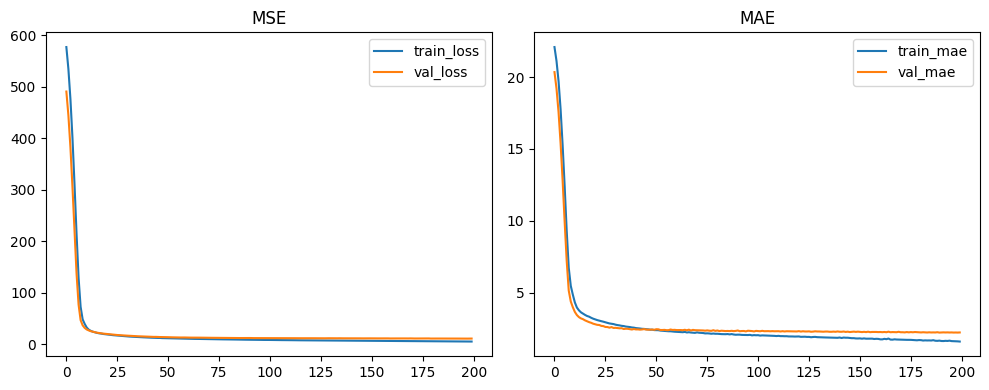

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
RMSE: 3.2544315420827834


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error

csv_path = 'BostonHousing.csv' if os.path.exists('BostonHousing.csv') else 'JS13/BostonHousing.csv'
if not os.path.exists(csv_path):
    url = 'https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv'
    df_boston = pd.read_csv(url)
else:
    df_boston = pd.read_csv(csv_path)

X_boston = df_boston.drop(columns=['medv']).values
y_boston = df_boston['medv'].values

scaler_b = StandardScaler()
Xs_boston = scaler_b.fit_transform(X_boston)

X_train_b, X_val_b, y_train_b, y_val_b = train_test_split(Xs_boston, y_boston, test_size=0.2, random_state=42)

model_boston = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_b.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model_boston.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

h_boston = model_boston.fit(X_train_b, y_train_b, validation_data=(X_val_b, y_val_b), epochs=200, batch_size=32, verbose=0)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(h_boston.history['loss'], label='train_loss')
plt.plot(h_boston.history['val_loss'], label='val_loss')
plt.title('MSE')
plt.legend()

plt.subplot(1,2,2)
plt.plot(h_boston.history['mae'], label='train_mae')
plt.plot(h_boston.history['val_mae'], label='val_mae')
plt.title('MAE')
plt.legend()
plt.tight_layout()
plt.show()

pred_b = model_boston.predict(X_val_b)
print('RMSE:', np.sqrt(mean_squared_error(y_val_b, pred_b)))

---
# Tugas Praktikum: Klasifikasi Angka Tulisan Tangan (MNIST) dengan JST

### 1. Load Dataset MNIST, Normalisasi, & One-Hot Encoding

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
import time

(X_train_m, y_train_m), (X_test_m, y_test_m) = mnist.load_data()

X_train_m = X_train_m / 255.0
X_test_m = X_test_m / 255.0

y_train_cat = to_categorical(y_train_m, 10)
y_test_cat = to_categorical(y_test_m, 10)

print(f"Dimensi Data Train: {X_train_m.shape}, Label Train: {y_train_cat.shape}")
print(f"Dimensi Data Test : {X_test_m.shape}, Label Test : {y_test_cat.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dimensi Data Train: (60000, 28, 28), Label Train: (60000, 10)
Dimensi Data Test : (10000, 28, 28), Label Test : (10000, 10)


### 2. Bangun Model JST Baseline (2 Hidden Layer) & Evaluasi

In [ ]:
model_mnist_base = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_mnist_base.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
model_mnist_base.fit(X_train_m, y_train_cat, epochs=10, batch_size=64, validation_split=0.1, verbose=1)
train_time_base = time.time() - start_time

loss_base, acc_base = model_mnist_base.evaluate(X_test_m, y_test_cat, verbose=0)
print(f"Akurasi Baseline: {acc_base:.4f} | Waktu Pelatihan: {train_time_base:.2f} detik")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9156 - loss: 0.2932 - val_accuracy: 0.9668 - val_loss: 0.1342
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9642 - loss: 0.1173 - val_accuracy: 0.9748 - val_loss: 0.0932
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9758 - loss: 0.0803 - val_accuracy: 0.9763 - val_loss: 0.0790
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9827 - loss: 0.0580 - val_accuracy: 0.9757 - val_loss: 0.0835
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9854 - loss: 0.0474 - val_accuracy: 0.9780 - val_loss: 0.0754
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9880 - loss: 0.0363 - val_accuracy: 0.9795 - val_loss: 0.0770
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9903 - loss: 0.0306 - val_accuracy: 0.9788 - val_loss: 0.0838
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9915 - loss: 0.0260 - val_accuracy: 0.

### 3. Eksperimen: Ubah Jumlah Neuron (256 & 128)

In [ ]:
model_mnist_wide = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_mnist_wide.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
model_mnist_wide.fit(X_train_m, y_train_cat, epochs=10, batch_size=64, validation_split=0.1, verbose=0)
train_time_wide = time.time() - start_time

loss_wide, acc_wide = model_mnist_wide.evaluate(X_test_m, y_test_cat, verbose=0)
print(f"Akurasi (256, 128): {acc_wide:.4f} | Waktu Pelatihan: {train_time_wide:.2f} detik")

Akurasi (256, 128): 0.9755 | Waktu Pelatihan: 53.23 detik


### 4. Eksperimen: Tambahkan 1 Hidden Layer Lagi (3 Hidden Layer: 256, 128, 64)

In [ ]:
model_mnist_deep = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_mnist_deep.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
model_mnist_deep.fit(X_train_m, y_train_cat, epochs=10, batch_size=64, validation_split=0.1, verbose=0)
train_time_deep = time.time() - start_time

loss_deep, acc_deep = model_mnist_deep.evaluate(X_test_m, y_test_cat, verbose=0)
print(f"Akurasi (3 Hidden Layer): {acc_deep:.4f} | Waktu Pelatihan: {train_time_deep:.2f} detik")

Akurasi (3 Hidden Layer): 0.9760 | Waktu Pelatihan: 56.52 detik


### 5. Eksperimen: Komparasi Fungsi Aktivasi Sigmoid vs ReLU

In [15]:
model_mnist_sigmoid = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='sigmoid'),
    Dense(64, activation='sigmoid'),
    Dense(10, activation='softmax')
])

model_mnist_sigmoid.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
model_mnist_sigmoid.fit(X_train_m, y_train_cat, epochs=10, batch_size=64, validation_split=0.1, verbose=0)
train_time_sigmoid = time.time() - start_time

loss_sig, acc_sig = model_mnist_sigmoid.evaluate(X_test_m, y_test_cat, verbose=0)
print(f"Akurasi Sigmoid: {acc_sig:.4f} | Waktu: {train_time_sigmoid:.2f} detik")
print(f"Akurasi ReLU   : {acc_base:.4f} | Waktu: {train_time_base:.2f} detik")

Akurasi Sigmoid: 0.9755 | Waktu: 37.81 detik
Akurasi ReLU   : 0.9741 | Waktu: 38.94 detik


### 6. Ringkasan Hasil Komparasi Tugas Praktikum MNIST

In [17]:
import pandas as pd

summary_data = {
    'Konfigurasi Model': [
        'Baseline (128-64, ReLU)',
        'Wider (256-128, ReLU)',
        'Deeper (256-128-64, ReLU)',
        'Sigmoid (128-64, Sigmoid)'
    ],
    'Akurasi Uji': [acc_base, acc_wide, acc_deep, acc_sig],
    'Waktu Latih (detik)': [train_time_base, train_time_wide, train_time_deep, train_time_sigmoid]
}

df_summary = pd.DataFrame(summary_data)
display(df_summary)

,Konfigurasi Model,Akurasi Uji,Waktu Latih (detik)
0,"Baseline (128-64, ReLU)",0.9741,38.943827
1,"Wider (256-128, ReLU)",0.9755,53.231847
2,"Deeper (256-128-64, ReLU)",0.9760,56.517751
3,"Sigmoid (128-64, Sigmoid)",0.9755,37.805538
